In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/gaia_dr3_100pc.csv")
df.shape

(228623, 10)

In [3]:
df.head()

,source_id,ra,dec,parallax,parallax_over_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe
0,139474737907945728,47.910022,37.387217,12.839739,753.58105,13.285183,14.406194,12.231950,2.174244,1.132158
1,140662927723337344,43.866383,36.565194,15.549707,801.63715,13.532904,14.768879,12.431154,2.337725,1.142346
2,141910534119968640,45.659626,36.442266,13.881536,283.38306,15.505523,17.151860,14.278165,2.873694,1.101566
3,142874737098263808,46.192166,39.212347,11.095036,588.10030,9.509297,9.853959,8.997155,0.856804,0.934500
4,143272554149050624,42.909296,38.046859,10.062697,631.73890,12.245269,12.954899,11.399982,1.554917,1.141644


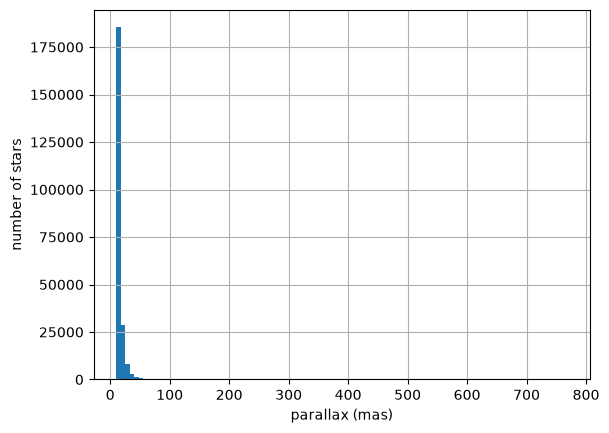

In [4]:
df["parallax"].hist(bins=100)
plt.xlabel("parallax (mas)")
plt.ylabel("number of stars")
plt.show()

absolute magnitude

In [5]:
df["M_G"] = df["phot_g_mean_mag"] + 5 * np.log10(df["parallax"]) - 10
df["M_G"].describe()

count    228623.000000
mean         10.189202
std           2.884965
min          -2.205333
25%           8.763256
50%          10.707375
75%          12.127546
max          19.049421
Name: M_G, dtype: float64

scatter plot

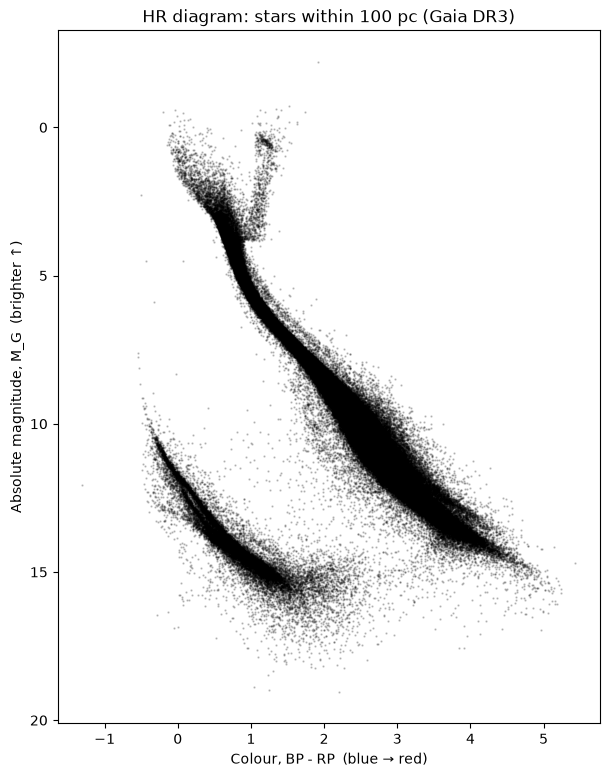

In [8]:
plt.figure(figsize=(7, 9))
plt.scatter(df["bp_rp"], df["M_G"], s=0.5, alpha=0.2, color="black")
plt.gca().invert_yaxis()
plt.xlabel("Colour, BP - RP  (blue → red)")
plt.ylabel("Absolute magnitude, M_G  (brighter ↑)")
plt.title("HR diagram: stars within 100 pc (Gaia DR3)")
plt.show()

density plot (hexbin)

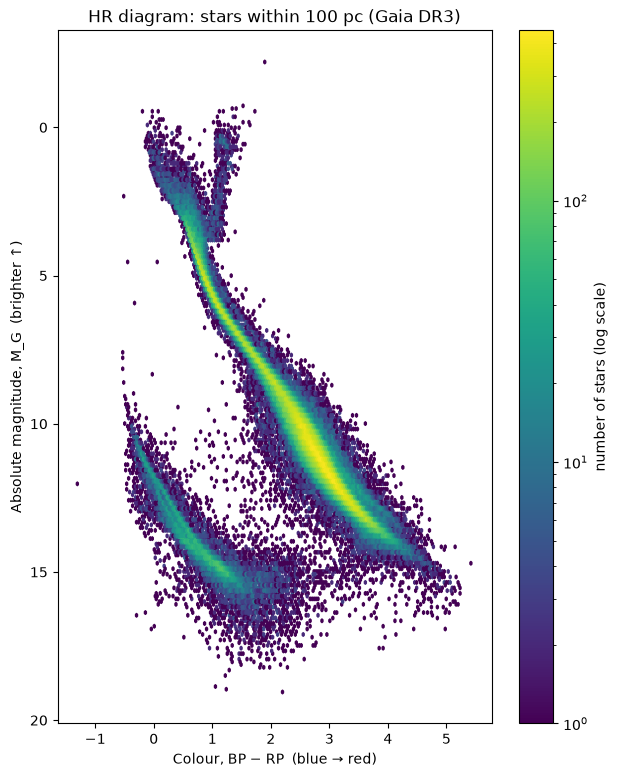

In [7]:
plt.figure(figsize=(7, 9))
plt.hexbin(df["bp_rp"], df["M_G"], gridsize=200, bins="log", cmap="viridis", mincnt=1)
plt.gca().invert_yaxis()
plt.colorbar(label="number of stars (log scale)")
plt.xlabel("Colour, BP − RP  (blue → red)")
plt.ylabel("Absolute magnitude, M_G  (brighter ↑)")
plt.title("HR diagram: stars within 100 pc (Gaia DR3)")
plt.show()

mark the sun

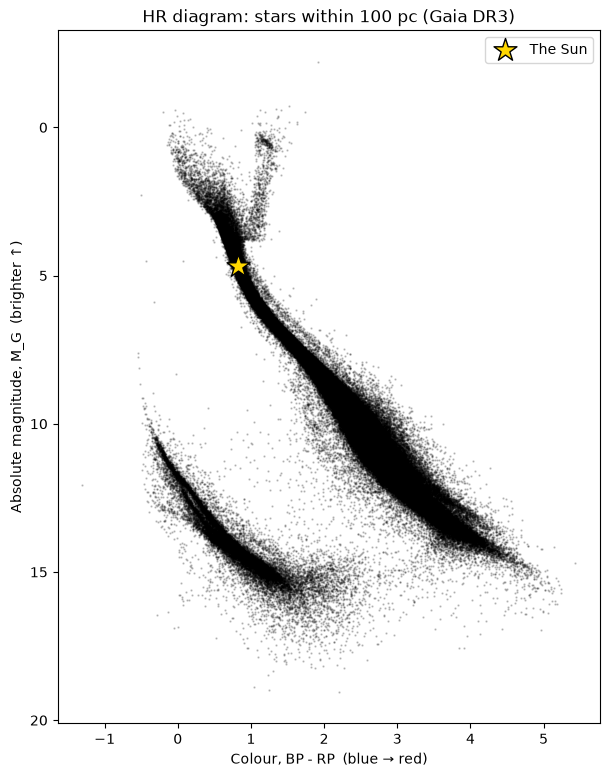

In [9]:
plt.figure(figsize=(7, 9))
plt.scatter(df["bp_rp"], df["M_G"], s=0.5, alpha=0.2, color="black")
plt.scatter(0.82, 4.67, s=300, marker="*", color="gold", edgecolor="black", zorder=3, label="The Sun")
plt.gca().invert_yaxis()
plt.xlabel("Colour, BP - RP  (blue → red)")
plt.ylabel("Absolute magnitude, M_G  (brighter ↑)")
plt.title("HR diagram: stars within 100 pc (Gaia DR3)")
plt.legend()
plt.show()

sort the stars into groups

In [10]:
is_wd = df["M_G"] > 3 * df["bp_rp"] + 9
is_giant = (df["M_G"] < 4) & (df["bp_rp"] > 0.9)
is_ms = ~is_wd & ~is_giant

print("White dwarfs: ", is_wd.sum())
print("Giants:       ", is_giant.sum())
print("Main sequence:", is_ms.sum())

White dwarfs:  18371
Giants:        991
Main sequence: 209261


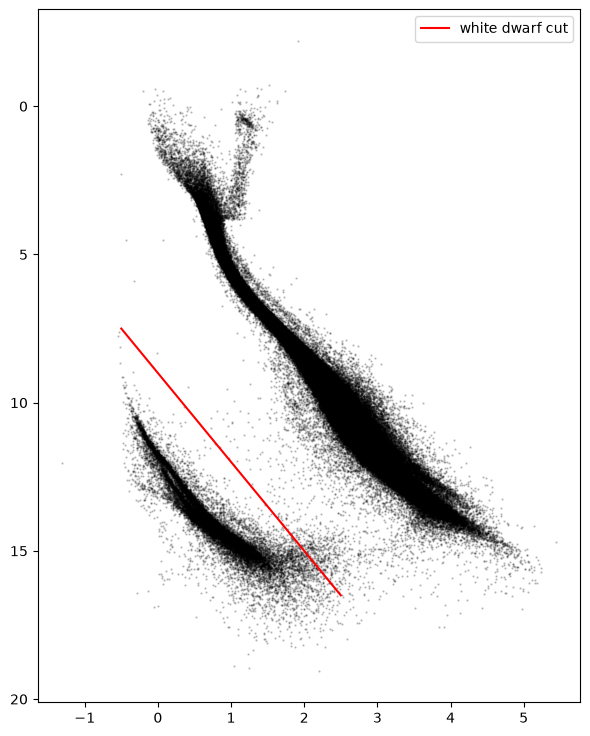

In [11]:
x = np.linspace(-0.5, 2.5, 100)

plt.figure(figsize=(7, 9))
plt.scatter(df["bp_rp"], df["M_G"], s=0.5, alpha=0.2, color="black")
plt.plot(x, 3 * x + 9, color="red", label="white dwarf cut")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

THE FINAL COLORED PLOT, SAVED

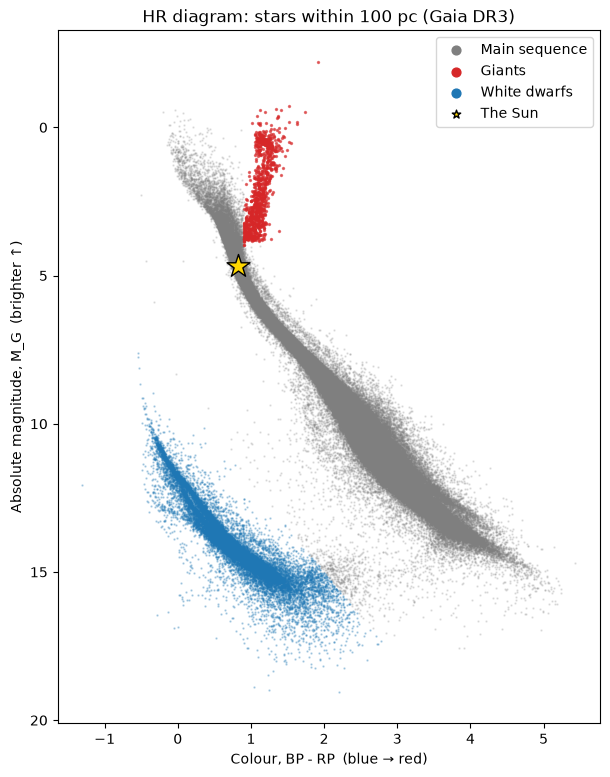

In [14]:
plt.figure(figsize=(7, 9))
plt.scatter(df.loc[is_ms, "bp_rp"], df.loc[is_ms, "M_G"], s=0.5, alpha=0.2, color="tab:gray", label="Main sequence")
plt.scatter(df.loc[is_giant, "bp_rp"], df.loc[is_giant, "M_G"], s=2, alpha=0.6, color="tab:red", label="Giants")
plt.scatter(df.loc[is_wd, "bp_rp"], df.loc[is_wd, "M_G"], s=0.5, alpha=0.3, color="tab:blue", label="White dwarfs")
plt.scatter(0.82, 4.67, s=300, marker="*", color="gold", edgecolor="black", zorder=3, label="The Sun")
plt.gca().invert_yaxis()
plt.xlabel("Colour, BP - RP  (blue → red)")
plt.ylabel("Absolute magnitude, M_G  (brighter ↑)")
plt.title("HR diagram: stars within 100 pc (Gaia DR3)")
leg = plt.legend(loc="upper right")
for handle in leg.legend_handles:
    handle.set_sizes([40])
    handle.set_alpha(1)
plt.savefig("../figures/hr_diagram_100pc.png", dpi=200, bbox_inches="tight")
plt.show()